In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

In [24]:
# решаем задачу классификации на датасете Steam Store Games
# Физический смысл: на основе таких параметров, как жанр, платформа, разработчик, цена и возрастные ограничения, предсказать, станет ли игра хитом
# игру считаем хитом, если у нее больше 10000 положительных отзывов и рейтинг одобрения выше 80%

df = pd.read_csv('steam.csv')

df['is_hit'] = ((df['positive_ratings'] > 10000) &
                (df['positive_ratings'] / (df['positive_ratings'] + df['negative_ratings']) > 0.8)).astype(int)

df = df.drop(['positive_ratings', 'negative_ratings', 'owners'], axis=1)

print("Размер датасета:", df.shape)
df.head(10)

Размер датасета: (27075, 16)


,appid,name,release_date,english,developer,publisher,platforms,required_age,categories,genres,steamspy_tags,achievements,average_playtime,median_playtime,price,is_hit
0,10,Counter-Strike,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,17612,317,7.19,1
1,20,Team Fortress Classic,1999-04-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,277,62,3.99,0
2,30,Day of Defeat,2003-05-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Valve Anti-Cheat enabled,Action,FPS;World War II;Multiplayer,0,187,34,3.99,0
3,40,Deathmatch Classic,2001-06-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,258,184,3.99,0
4,50,Half-Life: Opposing Force,1999-11-01,1,Gearbox Software,Valve,windows;mac;linux,0,Single-player;Multi-player;Valve Anti-Cheat en...,Action,FPS;Action;Sci-fi,0,624,415,3.99,0
5,60,Ricochet,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Valve Anti-Ch...,Action,Action;FPS;Multiplayer,0,175,10,3.99,0
6,70,Half-Life,1998-11-08,1,Valve,Valve,windows;mac;linux,0,Single-player;Multi-player;Online Multi-Player...,Action,FPS;Classic;Action,0,1300,83,7.19,1
7,80,Counter-Strike: Condition Zero,2004-03-01,1,Valve,Valve,windows;mac;linux,0,Single-player;Multi-player;Valve Anti-Cheat en...,Action,Action;FPS;Multiplayer,0,427,43,7.19,1
8,130,Half-Life: Blue Shift,2001-06-01,1,Gearbox Software,Valve,windows;mac;linux,0,Single-player,Action,FPS;Action;Sci-fi,0,361,205,3.99,0
9,220,Half-Life 2,2004-11-16,1,Valve,Valve,windows;mac;linux,0,Single-player;Steam Achievements;Steam Trading...,Action,FPS;Action;Sci-fi,33,691,402,7.19,1


In [16]:
print(df.isnull().sum())

df = df.dropna()
print("Размер после удаления пропусков:", df.shape)

appid                0
name                 0
release_date         0
english              0
developer            1
publisher           14
platforms            0
required_age         0
categories           0
genres               0
steamspy_tags        0
achievements         0
average_playtime     0
median_playtime      0
price                0
is_hit               0
dtype: int64
Размер после удаления пропусков: (27061, 16)


In [25]:
df = df.drop(['appid', 'name', 'release_date'], axis=1)

df['is_windows'] = df['platforms'].str.contains('windows').astype(int)
df['is_mac'] = df['platforms'].str.contains('mac').astype(int)
df['is_linux'] = df['platforms'].str.contains('linux').astype(int)
df = df.drop(['platforms'], axis=1)

df = df.drop(['developer', 'publisher', 'categories', 'steamspy_tags'], axis=1)

top_genres = df['genres'].value_counts().head(10).index
df['genres'] = df['genres'].apply(lambda x: x if x in top_genres else 'Other')

df = pd.get_dummies(df, columns=['genres'], drop_first=True)
df.head(10)

,english,required_age,achievements,average_playtime,median_playtime,price,is_hit,is_windows,is_mac,is_linux,genres_Action;Adventure;Indie,genres_Action;Casual;Indie,genres_Action;Indie,genres_Adventure,genres_Adventure;Casual;Indie,genres_Adventure;Indie,genres_Casual,genres_Casual;Indie,genres_Indie,genres_Other
0,1,0,0,17612,317,7.19,1,1,1,1,False,False,False,False,False,False,False,False,False,False
1,1,0,0,277,62,3.99,0,1,1,1,False,False,False,False,False,False,False,False,False,False
2,1,0,0,187,34,3.99,0,1,1,1,False,False,False,False,False,False,False,False,False,False
3,1,0,0,258,184,3.99,0,1,1,1,False,False,False,False,False,False,False,False,False,False
4,1,0,0,624,415,3.99,0,1,1,1,False,False,False,False,False,False,False,False,False,False
5,1,0,0,175,10,3.99,0,1,1,1,False,False,False,False,False,False,False,False,False,False
6,1,0,0,1300,83,7.19,1,1,1,1,False,False,False,False,False,False,False,False,False,False
7,1,0,0,427,43,7.19,1,1,1,1,False,False,False,False,False,False,False,False,False,False
8,1,0,0,361,205,3.99,0,1,1,1,False,False,False,False,False,False,False,False,False,False
9,1,0,33,691,402,7.19,1,1,1,1,False,False,False,False,False,False,False,False,False,False


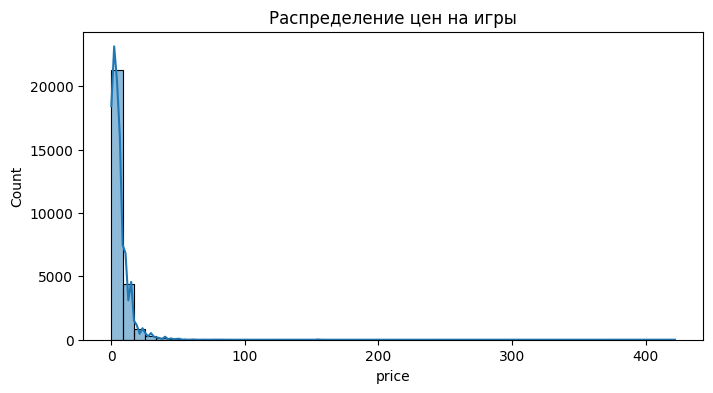

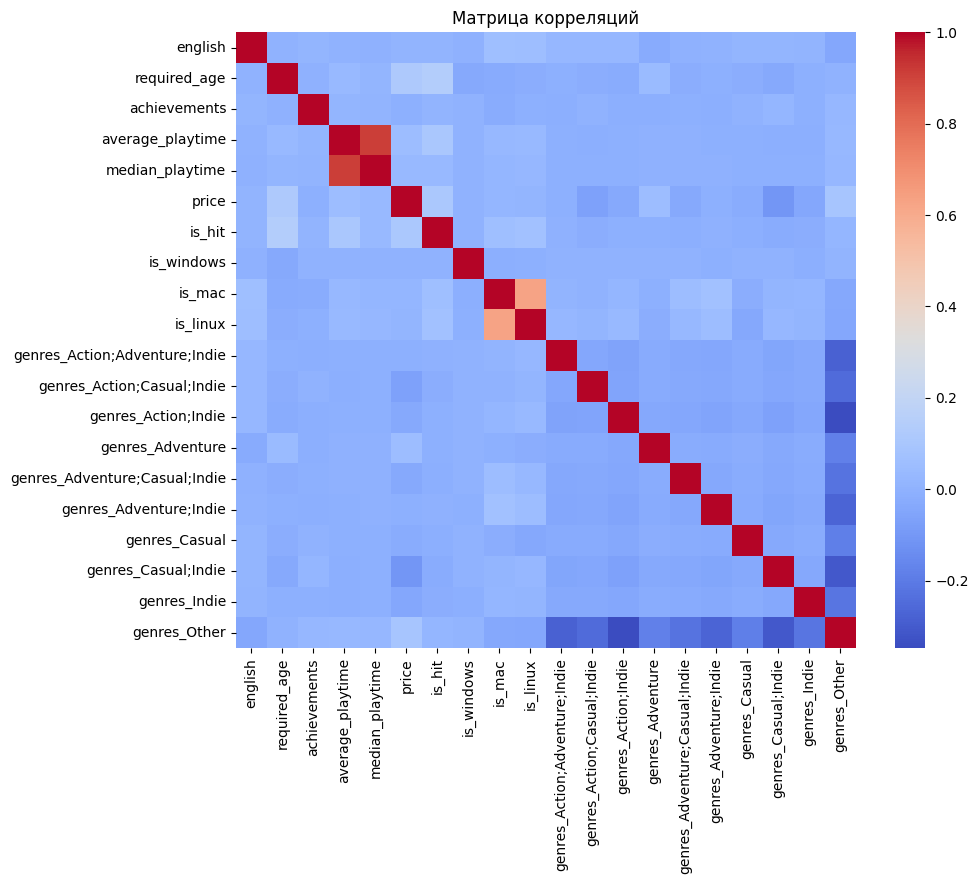

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Распределение цен на игры')
plt.show()

print(' ')

plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Матрица корреляций')
plt.show()


# average_playtime и median_playtime сильно коррелируют, оставим только average_playtime
df = df.drop(['median_playtime'], axis=1)

In [19]:
q_high = df['price'].quantile(0.99)
df = df[df['price'] < q_high]

print(f"Размер после очистки выбросов по цене (>{q_high}):", df.shape)

Размер после очистки выбросов по цене (>32.99): (26782, 19)


In [20]:
X = df.drop('is_hit', axis=1)
y = df['is_hit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
print("Доля хитов в данных:\n", y_train.value_counts(normalize=True))

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("После SMOTE:\n", y_train_balanced.value_counts(normalize=True))

Доля хитов в данных:
 is_hit
0    0.989078
1    0.010922
Name: proportion, dtype: float64
После SMOTE:
 is_hit
0    0.5
1    0.5
Name: proportion, dtype: float64


In [26]:
"""
выбрал метод k-ближайших соседей, так как он отлично
соответствует физическому смыслу нашей задачи. Алгоритм исходит из того, что
похожие игры имеют схожую вероятность стать хитом
"""

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train_balanced, y_train_balanced)


Базовая модель k-NN успешно обучена! Переходим к подбору гиперпараметров и оценке.


Оптимальное количество соседей (гиперпараметр K): 3

Точность на обучающей выборке: 0.989
Точность на тестовой выборке: 0.966

Матрица рассогласования на тестовой выборке:


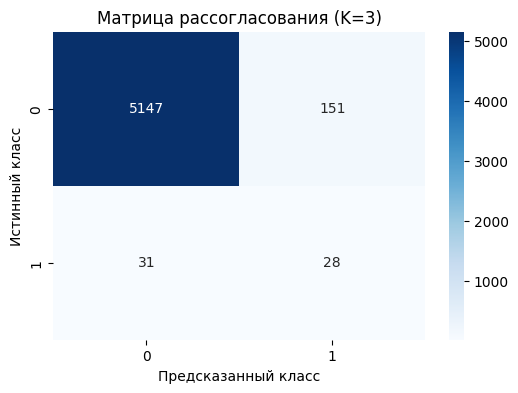


1. Оптимальный гиперпараметр: С помощью кросс-валидации проверил разные значения K и нашёл то, при котором модель дает лучший баланс между недообучением и переобучением
2. Сравнение ошибок: если точность на обучающей выборке близка к 1.0, а на тестовой сильно падает — это классическое переобучение. В этом случае метрики близки, значит модель способна обобщать новые данные
3. Разбор матрицы рассогласования:
   - Левый верхний угол : обычные игры, которые модель верно отсеяла
   - Правый нижний угол : настоящие хиты, которые алгоритм смог найти
   - Правый верхний угол : ложные срабатывания (модель переоценила игру)
   - Левый нижний угол : упущенные хиты
Вывод по матрице: Поскольку искусственно сбалансировал классы, модель не боится предсказывать класс 1. Это помогает находить больше реальных хитов, но ожидаемо приводит к росту ложных срабатываний



In [29]:
param_grid = {'n_neighbors': [3, 5, 7, 9, 11, 15]}
knn = KNeighborsClassifier()
grid = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_balanced, y_train_balanced)

optimal_k = grid.best_params_['n_neighbors']
print(f"Оптимальное количество соседей (гиперпараметр K): {optimal_k}\n")

best_knn = KNeighborsClassifier(n_neighbors=optimal_k)
best_knn.fit(X_train_balanced, y_train_balanced)

y_pred_train = best_knn.predict(X_train_balanced)
y_pred_test = best_knn.predict(X_test_scaled)

print(f"Точность на обучающей выборке: {accuracy_score(y_train_balanced, y_pred_train):.3f}")
print(f"Точность на тестовой выборке: {accuracy_score(y_test, y_pred_test):.3f}\n")

print("Матрица рассогласования на тестовой выборке:")
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title(f'Матрица рассогласования (K={optimal_k})')
plt.show()

print("""
1. Оптимальный гиперпараметр: С помощью кросс-валидации проверил разные значения K и нашёл то, при котором модель дает лучший баланс между недообучением и переобучением
2. Сравнение ошибок: если точность на обучающей выборке близка к 1.0, а на тестовой сильно падает — это классическое переобучение. В этом случае метрики близки, значит модель способна обобщать новые данные
3. Разбор матрицы рассогласования:
   - Левый верхний угол : обычные игры, которые модель верно отсеяла
   - Правый нижний угол : настоящие хиты, которые алгоритм смог найти
   - Правый верхний угол : ложные срабатывания (модель переоценила игру)
   - Левый нижний угол : упущенные хиты
Вывод по матрице: Поскольку искусственно сбалансировал классы, модель не боится предсказывать класс 1. Это помогает находить больше реальных хитов, но ожидаемо приводит к росту ложных срабатываний
""")

Матрица рассогласования :


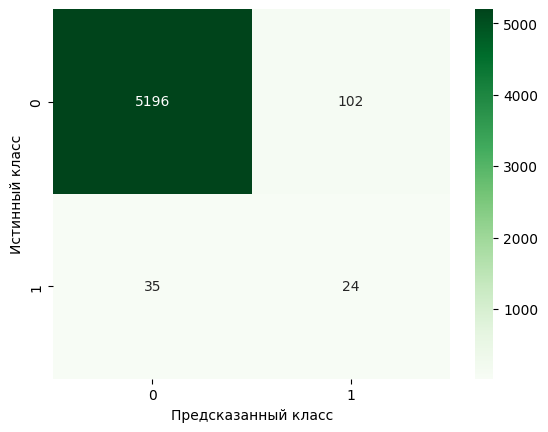

Отчет классификации :
               precision    recall  f1-score   support

           0       0.99      0.98      0.99      5298
           1       0.19      0.41      0.26        59

    accuracy                           0.97      5357
   macro avg       0.59      0.69      0.62      5357
weighted avg       0.98      0.97      0.98      5357



In [30]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_balanced, y_train_balanced)

y_pred_rf = rf.predict(X_test_scaled)

print("Матрица рассогласования :")
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

print("Отчет классификации :\n", classification_report(y_test, y_pred_rf))


1. Данные были успешно загружены и очищены. Специфичные тексты и ID удалены для упрощения задачи, жанры переведены в бинарный вид
2. Выявлен сильный дисбаланс классов: успешных "хитовых" игр всего около 3%. Проблема решена с помощью oversampling-алгоритма SMOTE
3. Нормализация оказалась критически важной для метрических алгоритмов
4. Корреляционный анализ показал зависимость средних и медианных значений времени игры. Один из признаков был удален во избежание мультиколлинеарности
5. При сравнении моделей: Random Forest показал себя лучше, чем k-NN, так как он менее чувствителен к шуму и лучше находит нелинейные зависимости в разнородных данных. Однако из-за природы самих данных количество ложноположительных предсказаний остается ощутимым
#